# Linear Support Vector Classifier on the Iris Dataset

This notebook trains a linear support vector classifier (SVC) on two classes of the Iris dataset, using only the two sepal features so that the decision boundary and margins can be drawn directly. The main question is how the regularisation parameter `C` changes the margin.

In [28]:
# imports
import numpy as np
from sklearn import datasets
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
%matplotlib inline

## Data

Only sepal length and sepal width are used. Virginica is removed, which leaves setosa (0) and versicolor (1), with 50 samples each.

In [29]:
# loading the dataset and normalize the features
iris = datasets.load_iris()
X = iris['data'][:,(0,1)]

In [30]:
Y= iris['target']
X=X[Y!=2]
Y=Y[Y!=2]
print("Input features: ")
print(X[:5])
print("Target labels: ")
print(Y[:5])

Input features: 
[[5.1 3.5]
 [4.9 3. ]
 [4.7 3.2]
 [4.6 3.1]
 [5.  3.6]]
Target labels: 
[0 0 0 0 0]


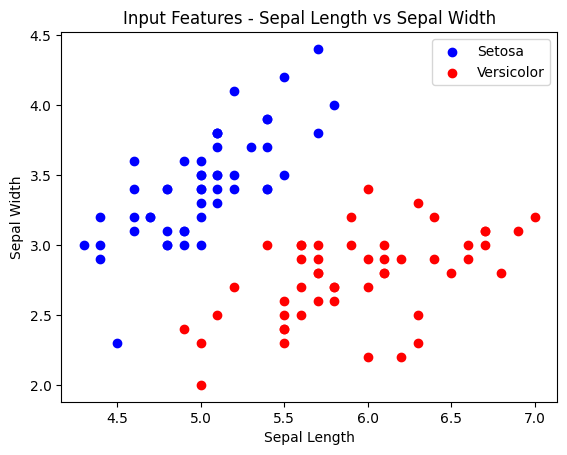

In [31]:
plt.scatter(X[Y==0,0],X[Y==0,1],color="blue",label="Setosa")
plt.scatter(X[Y==1,0],X[Y==1,1],color="red",label="Versicolor")
plt.title("Input Features - Sepal Length vs Sepal Width")
plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.legend()
plt.show()

Setosa sits in the upper left and versicolor in the lower right. A straight line separates most of the points, although a few samples lie close to the boundary, so the margin will matter here.

## Train-Test Split and Scaling

The data is split 80/20. Support vector machines are sensitive to feature scale, so both features are standardised. The scaler is fitted on the training set only, to avoid leaking information from the test set, and the same scaled data is used for both models. That keeps the comparison between the two values of `C` fair.

In [32]:
x,y=X,Y
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [33]:
# fit the scaler on the training data only
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)
X_scaled = scaler.transform(x)

## SVC with C = 1

Iterations: 35
Weights:  [[ 1.8576509  -1.55856208]]
Intercept:  [0.38571357]


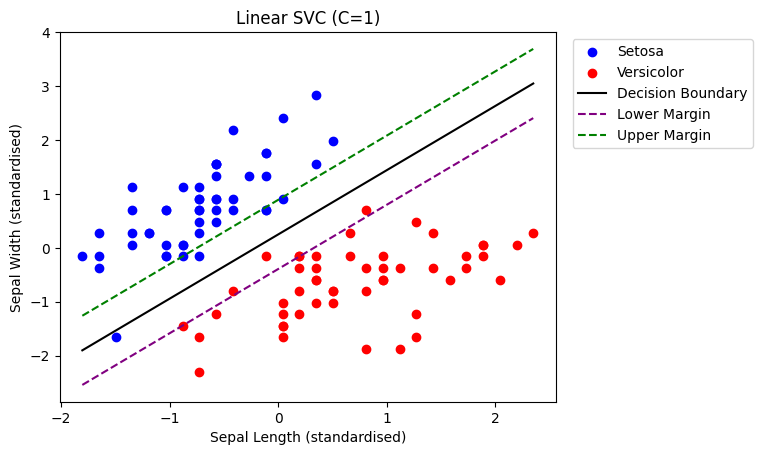

Accuracy:  1.0
Margin width: 0.8247873176609442
Training accuracy: 0.9875


In [34]:
model=LinearSVC(C=1,loss='hinge')
model.fit(x_train_scaled,y_train)
print("Iterations:", model.n_iter_)
print("Weights: ",model.coef_)
print("Intercept: ",model.intercept_)
x_value=np.linspace(X_scaled[ : ,0].min() ,X_scaled[ : ,0].max(), 100)
y_value= -(model.coef_[0,0] * x_value + model.intercept_[0])/model.coef_[0,1]
y_margin1= (1-model.coef_[0][0] * x_value - model.intercept_[0])/model.coef_[0][1]
y_margin2= -(1+model.coef_[0][0] * x_value + model.intercept_[0])/model.coef_[0][1]
plt.scatter(X_scaled[y==0,0],X_scaled[y==0,1],color="blue",label="Setosa")
plt.scatter(X_scaled[y==1,0],X_scaled[y==1,1],color="red",label="Versicolor")
plt.plot(x_value,y_value,color="black",label="Decision Boundary")
plt.plot(x_value,y_margin1,linestyle="--",color="purple",label="Lower Margin")
plt.plot(x_value,y_margin2,linestyle="--",color="green",label="Upper Margin")
plt.title("Linear SVC (C=1)")
plt.xlabel("Sepal Length (standardised)")
plt.ylabel("Sepal Width (standardised)")
plt.legend(bbox_to_anchor=(1.02,1), loc="upper left")
plt.show()
y_pred=model.predict(x_test_scaled)
print("Accuracy: ",accuracy_score(y_test,y_pred))
print("Margin width:", 2/np.linalg.norm(model.coef_))
print("Training accuracy:", accuracy_score(y_train, model.predict(x_train_scaled)))

With `C=1` the margin is wide (about 0.82 in standardised units). Several points fall inside it, and one training sample is misclassified. A small `C` penalises these violations only lightly, so the model accepts a few of them in exchange for a wider margin. All 20 test samples are still classified correctly.

## SVC with C = 1000

iterations:  164
Weights:  [[ 4.10631969 -2.4608415 ]]
Intercept:  [1.06314924]


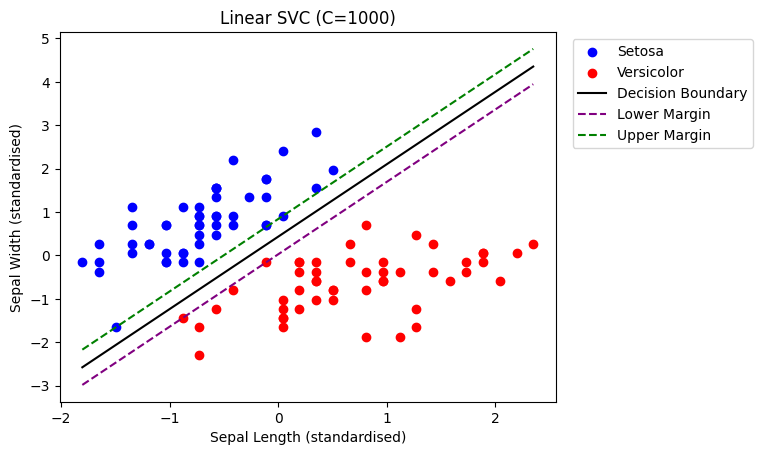

Accuracy:  1.0
Margin width: 0.41777784572646554
Training accuracy: 1.0


In [35]:
model=LinearSVC(C=1000,loss='hinge')
model.fit(x_train_scaled,y_train)
print("iterations: ",model.n_iter_)
print("Weights: ",model.coef_)
print("Intercept: ",model.intercept_)
x_value=np.linspace(X_scaled[ : ,0].min() ,X_scaled[ : ,0].max(), 100)
y_value= -(model.coef_[0,0] * x_value + model.intercept_[0])/model.coef_[0,1]
y_margin1= (1-model.coef_[0][0] * x_value - model.intercept_[0])/model.coef_[0][1]
y_margin2= -(1+model.coef_[0][0] * x_value + model.intercept_[0])/model.coef_[0][1]
plt.scatter(X_scaled[y==0,0],X_scaled[y==0,1],color="blue",label="Setosa")
plt.scatter(X_scaled[y==1,0],X_scaled[y==1,1],color="red",label="Versicolor")
plt.plot(x_value,y_value,color="black",label="Decision Boundary")
plt.plot(x_value,y_margin1,linestyle="--",color="purple",label="Lower Margin")
plt.plot(x_value,y_margin2,linestyle="--",color="green",label="Upper Margin")
plt.title("Linear SVC (C=1000)")
plt.xlabel("Sepal Length (standardised)")
plt.ylabel("Sepal Width (standardised)")
plt.legend(bbox_to_anchor=(1.02,1), loc="upper left")
plt.show()
y_pred=model.predict(x_test_scaled)
print("Accuracy: ",accuracy_score(y_test,y_pred))
print("Margin width:", 2/np.linalg.norm(model.coef_))
print("Training accuracy:", accuracy_score(y_train, model.predict(x_train_scaled)))

With `C=1000` the margin narrows to about 0.42, roughly half of the previous width. Violations are now penalised heavily, so the model fits the training data perfectly. Test accuracy is again 100%.

## Conclusions

Both models reach 100% test accuracy, so the test set does not separate them. The 20 test samples are too few for that, and the two classes are largely separable in any case. The difference appears in the margins: a small `C` gives a wide margin that tolerates some errors, while a large `C` gives a narrow margin that fits the training points exactly.

A natural next step is to choose `C` by cross-validation instead of comparing two fixed values.